In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("data/processed/student_performance_clean.csv")
subjects = ["Mathematics", "Python_Programming", "Computer_Fundamentals", "English", "Statistics"]
df["Average_Marks"] = df[subjects].mean(axis=1).round(2)   # each student's average
os.makedirs("outputs/figures", exist_ok=True)               # folder for charts
print(df.shape)

(200, 11)


In [2]:
print(df[subjects].agg(["mean", "median", "min", "max", "std"]).round(2).T)
means = df[subjects].mean().round(2)
print("\nHighest average:", means.idxmax(), means.max())
print("Lowest average:", means.idxmin(), means.min())
print(df[["Attendance_Percent", "Study_Hours_Per_Week"]].describe().round(2))

                        mean  median   min   max    std
Mathematics            50.11    50.0  17.0  74.0  10.06
Python_Programming     56.16    56.0  26.0  82.0   9.52
Computer_Fundamentals  60.30    61.0  36.0  94.0   9.86
English                55.99    55.0  27.0  82.0  10.30
Statistics             48.10    48.0  19.0  75.0  10.22

Highest average: Computer_Fundamentals 60.3
Lowest average: Statistics 48.1
       Attendance_Percent  Study_Hours_Per_Week
count              200.00                200.00
mean                75.49                  9.77
std                 11.04                  4.07
min                 40.00                  1.00
25%                 67.42                  6.88
50%                 75.80                  9.75
75%                 82.65                 12.50
max                100.00                 22.30


In [3]:
PASS_MARK = 40     # CHANGE THIS to your college's pass mark

passed = df[subjects] >= PASS_MARK                   # True/False for every mark
print("Subject-wise pass %:")
print((passed.mean() * 100).round(1))
print("\nPassed ALL subjects: ", round(passed.all(axis=1).mean() * 100, 1), "%")

Subject-wise pass %:
Mathematics              87.0
Python_Programming       95.5
Computer_Fundamentals    98.0
English                  96.0
Statistics               82.5
dtype: float64

Passed ALL subjects:  72.0 %


In [4]:
df["Attendance_Group"] = pd.cut(df["Attendance_Percent"], bins=[0, 60, 75, 90, 100],
                                labels=["<60", "60-75", "75-90", "90-100"])
df["Study_Group"] = pd.cut(df["Study_Hours_Per_Week"], bins=[0, 6, 10, 14, 30],
                           labels=["0-6", "6-10", "10-14", "14+"])
print(df.groupby("Attendance_Group", observed=True)["Average_Marks"].agg(["count", "mean"]).round(2))
print(df.groupby("Study_Group", observed=True)["Average_Marks"].agg(["count", "mean"]).round(2))

                  count   mean
Attendance_Group              
<60                  15  47.59
60-75                77  52.35
75-90                90  55.40
90-100               18  60.87
             count   mean
Study_Group              
0-6             36  46.94
6-10            70  52.45
10-14           65  56.42
14+             29  61.97


In [5]:
cols = ["Attendance_Percent", "Study_Hours_Per_Week"] + subjects + ["Average_Marks"]
corr = df[cols].corr().round(2)
print(corr[["Average_Marks"]])

                       Average_Marks
Attendance_Percent              0.44
Study_Hours_Per_Week            0.69
Mathematics                     0.72
Python_Programming              0.75
Computer_Fundamentals           0.68
English                         0.72
Statistics                      0.71
Average_Marks                   1.00


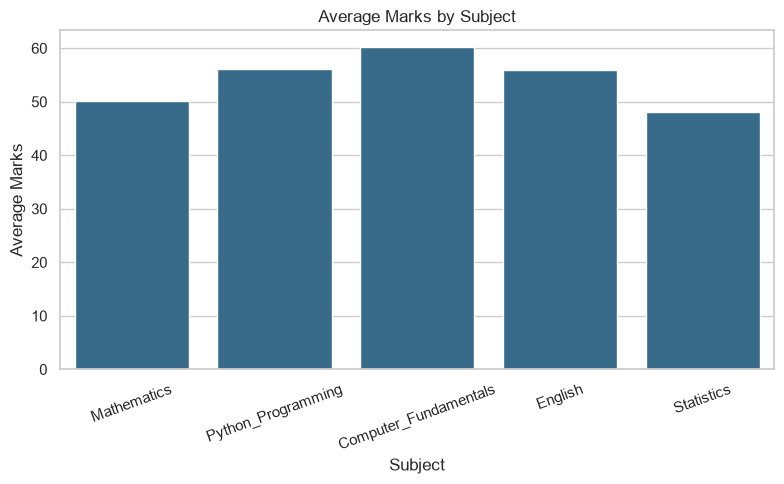

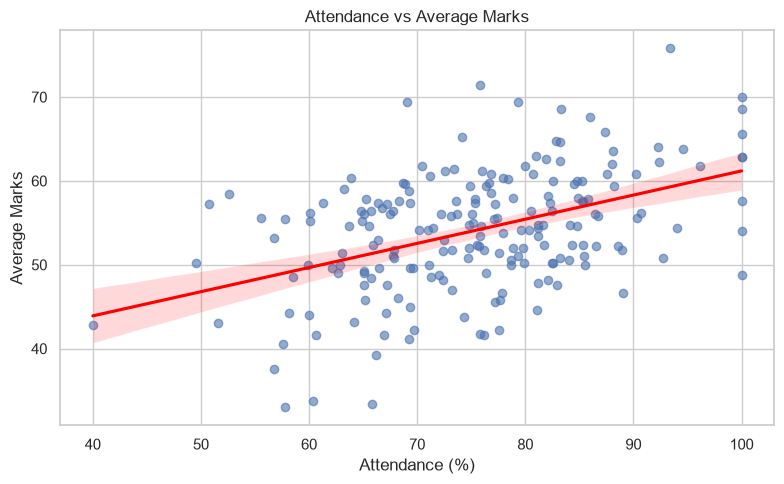

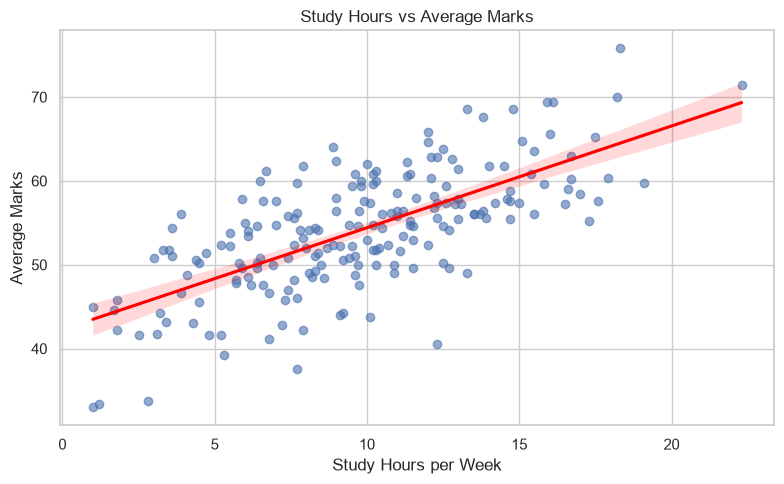

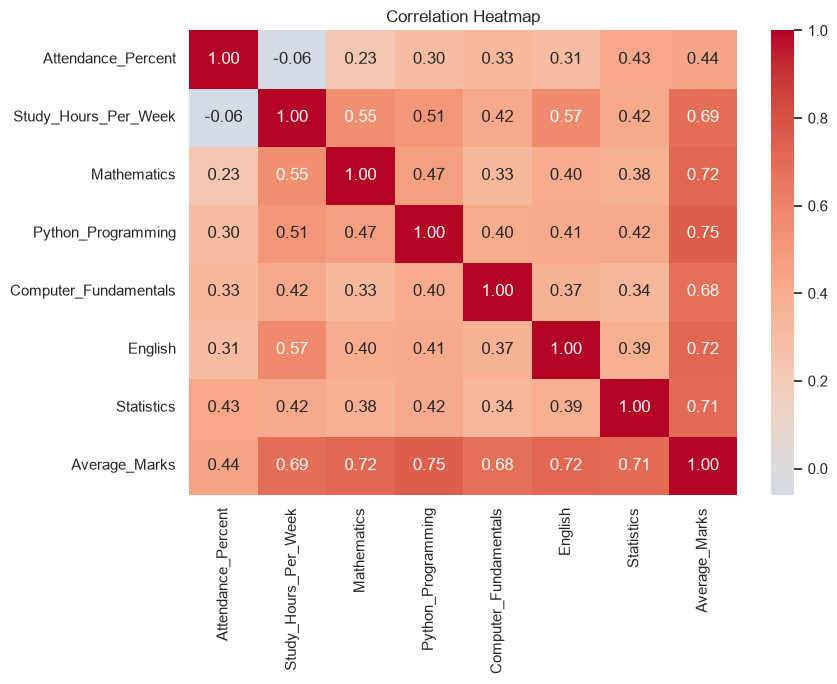

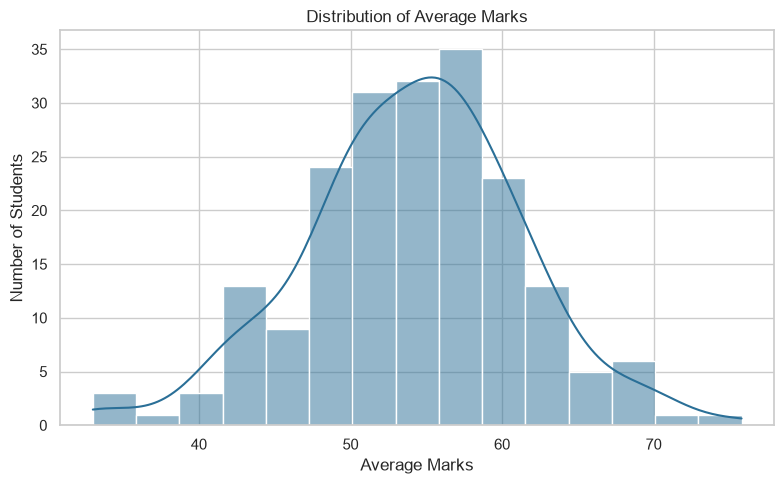

In [6]:
sns.set_theme(style="whitegrid")

# 1. Subject-wise average marks
plt.figure(figsize=(8, 5))
sns.barplot(x=means.index, y=means.values, color="#2a6f97")
plt.title("Average Marks by Subject"); plt.xlabel("Subject"); plt.ylabel("Average Marks")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("outputs/figures/1_subject_avg.png", dpi=150); plt.show()

# 2. Attendance vs marks
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Attendance_Percent", y="Average_Marks",
            scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
plt.title("Attendance vs Average Marks"); plt.xlabel("Attendance (%)"); plt.ylabel("Average Marks")
plt.tight_layout(); plt.savefig("outputs/figures/2_attendance_vs_marks.png", dpi=150); plt.show()

# 3. Study time vs marks
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Study_Hours_Per_Week", y="Average_Marks",
            scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
plt.title("Study Hours vs Average Marks"); plt.xlabel("Study Hours per Week"); plt.ylabel("Average Marks")
plt.tight_layout(); plt.savefig("outputs/figures/3_study_vs_marks.png", dpi=150); plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap"); plt.tight_layout()
plt.savefig("outputs/figures/4_heatmap.png", dpi=150); plt.show()

# 5. Marks distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Average_Marks"], bins=15, kde=True, color="#2a6f97")
plt.title("Distribution of Average Marks"); plt.xlabel("Average Marks"); plt.ylabel("Number of Students")
plt.tight_layout(); plt.savefig("outputs/figures/5_distribution.png", dpi=150); plt.show()